**Vision-Based Gaze Estimation | Presented by: Reza Saadatyar (2026)**

**01 | MPIIGaze Source Audit and Participant-Level Protocol**

![MPIIGaze archive structure, participant/day support and participant-level evaluation design](../../images/01_mpiigaze_source_audit_and_protocol.svg)

**Objective:** Inspect the source files and participant/day MATLAB structure, and define an evaluation design for unseen-person gaze estimation.

**Dataset:** [MPIIGaze](https://www.collaborative-ai.org/research/datasets/MPIIGaze/) / [DaRUS archive](https://doi.org/10.18419/darus-3230). The authors report 213,659 collected images from 15 people. The archive audit identified 15 participants and 521 normalised participant/day MAT containers.

**Scope:** Source inventory, participant support, representative MATLAB headers and publisher list metadata. Notebook 02 examines image–target alignment and the normalised gaze coordinate frame.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("vision_based_gaze_estimation")

# ---------------------------- 2. Standard Library ----------------------------
import shutil
import sys

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 5. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from mpiigaze_io import (
    SOURCE_PAGE, SOURCE_DOI, ensure_mpiigaze_source,
    source_inventory, participant_source_support, inspect_mat_header,
    is_archive_companion, is_normalised_mat_path,
)

# ------------------------ 6. Output and Source Paths -------------------------
study = root / "vision_based_gaze_estimation"
output_dir = study / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = root / "data" / "raw" / "mpiigaze"
raw_dir.parent.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)
print("Study outputs:", output_dir)
print("Source directory:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(shutil.disk_usage(raw_dir.parent).free / 2**30, 2))


Repository up to date.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/vision_based_gaze_estimation/output
Source directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/mpiigaze
Python: 3.13.16
Free disk (GiB): 112.28


**02. Locate or Acquire the MPIIGaze Source**

MPIIGaze is available for non-commercial research. The source adapter reuses extracted data or a cached archive; otherwise it downloads and extracts the official distribution in the runtime. Raw data remain in `data/raw/mpiigaze/`.

In [3]:
# ==================== 02. Locate Official MPIIGaze Source ====================

# --------------------- 1. Acquire or Reuse Original Data ---------------------
raw_dir = ensure_mpiigaze_source(raw_dir)

# ------------------------- 2. Report Runtime Source --------------------------
print("Source directory:", raw_dir)
print("Official source:", SOURCE_PAGE)
print("Archive reference:", SOURCE_DOI)

Retrieving official MPIIGaze archive: https://collaborative-ai.org/files/datasets/MPIIGaze.tar.gz
Source acquisition attempt failed: MPIIGaze.tar.gz: HTTPError: HTTP Error 404: Not Found
Retrieving official MPIIGaze archive: https://darus.uni-stuttgart.de/api/access/datafile/:persistentId?persistentId=doi:10.18419/DARUS-3230/1
Downloaded 256 MiB
Downloaded 512 MiB
Downloaded 768 MiB
Downloaded 1,024 MiB
Downloaded 1,280 MiB
Downloaded 1,536 MiB
Downloaded 1,792 MiB
Downloaded 2,048 MiB
Archive received: 2.16 GiB
Extracting original MPIIGaze files in the runtime...
Source available: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/mpiigaze
Normalised MAT containers: 521
Source directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/mpiigaze
Official source: https://www.collaborative-ai.org/research/datasets/MPIIGaze/
Archive reference: https://doi.org/10.18419/darus-3230


**03. Audit Original Source Files**

The inventory records 430,180 archive file paths: 215,386 operating-system companion paths and 214,794 non-companion paths. The normalised component contains 521 participant/day MAT files. These counts describe files, not individual images; a MAT container can hold multiple image and target records.

In [4]:
# =================== 03. Audit Source Files and Provenance ===================

# ---------------------- 1. Build the Observed Inventory ----------------------
inventory = source_inventory(raw_dir)
if inventory.empty or inventory.relative_path.duplicated().any():
    raise ValueError("Source files missing or duplicated")
inventory.to_csv(output_dir / "01_file_inventory.csv", index=False)

# ---------------------- 2. Separate Archive Companions -----------------------
companion = inventory.relative_path.map(is_archive_companion)
scientific = inventory.loc[~companion]
normalized = inventory.loc[
    inventory.relative_path.map(is_normalised_mat_path)
].sort_values(["participant_id", "relative_path"])
if normalized.empty:
    raise ValueError("No participant/day normalised MAT files found")
print("Archive file paths:", len(inventory))
print("Archive companion paths:", int(companion.sum()))
print("Participant/day MAT paths:", len(normalized))
display(scientific.groupby("component").agg(
    files=("relative_path", "size"),
    mebibytes=("size_bytes", lambda x: round(x.sum() / 2**20, 1)),
).reset_index())
display(inventory.head(12))

Archive file paths: 430180
Archive companion paths: 215386
Participant/day MAT paths: 521


,component,files,mebibytes
0,Annotation Subset,15,0.8
1,Evaluation Subset,31,3.1
2,Normalized,521,834.8
3,Original,214224,4092.5
4,Other,3,0.0


,relative_path,component,participant_id,recording_day,suffix,size_bytes
0,MPIIGaze/.DS_Store,Other,None,None,,6148
1,MPIIGaze/6 points-based face model.mat,Other,None,None,.mat,336
2,MPIIGaze/Annotation Subset/p00.txt,Annotation Subset,None,None,.txt,68493
3,MPIIGaze/Annotation Subset/p01.txt,Annotation Subset,None,None,.txt,67941
4,MPIIGaze/Annotation Subset/p02.txt,Annotation Subset,None,None,.txt,82160
5,MPIIGaze/Annotation Subset/p03.txt,Annotation Subset,None,None,.txt,50481
6,MPIIGaze/Annotation Subset/p04.txt,Annotation Subset,None,None,.txt,68888
7,MPIIGaze/Annotation Subset/p05.txt,Annotation Subset,None,None,.txt,74260
8,MPIIGaze/Annotation Subset/p06.txt,Annotation Subset,None,None,.txt,70389
9,MPIIGaze/Annotation Subset/p07.txt,Annotation Subset,None,None,.txt,60988


**04. Audit Participant and Day Support**

All 15 participants (p00–p14) have normalised MAT paths, ranging from 7 to 69 day containers per participant. Of the 1,042 normalised MAT candidate paths, 521 are operating-system companions. The `normalised_mat_files` column counts only the 521 participant/day containers; `source_files` and `original_files` retain archive-level path counts.

In [5]:
# =================== 04. Audit Participant and Day Support ===================

# --------------- 1. Summarise Participant Source Availability ----------------
support = participant_source_support(inventory)
if support.empty or support.participant_id.duplicated().any():
    raise ValueError("No participant folder identifiers found")
support.to_csv(output_dir / "01_participant_support.csv", index=False)
display(support)
print("Participants with normalised MAT paths:",
      support.normalised_mat_files.gt(0).sum())

,participant_id,source_files,normalised_mat_candidate_paths,normalised_mat_files,original_files,calibration_files,observed_day_folders
0,p00,60126,78,39,60048,0,39
1,p01,48638,138,69,48500,0,69
2,p02,56242,78,39,56164,0,39
3,p03,70484,130,65,70354,0,65
4,p04,33796,50,25,33746,0,25
5,p05,33351,76,38,33275,0,38
6,p06,37213,124,62,37089,0,62
7,p07,31305,112,56,31193,0,56
8,p08,21644,94,47,21550,0,47
9,p09,16099,40,20,16059,0,20


Participants with normalised MAT paths: 15


**05. Inspect Normalised MATLAB Schemas**

One representative day container per participant was inspected. All 15 headers use MATLAB v5 and contain two top-level variables: a `data` structure and a `filenames` cell array. The 30 header records establish the outer MAT structure, while nested image and gaze fields and their row correspondence are examined in Notebook 02.

In [6]:
# =================== 05. Inspect Normalised MATLAB Schemas ===================

# ------------------ 1. Select One Container per Participant ------------------
representatives = normalized.drop_duplicates("participant_id")
schema_rows = []
for item in representatives.itertuples(index=False):
    for variable in inspect_mat_header(raw_dir / item.relative_path):
        schema_rows.append({
            "participant_id": item.participant_id,
            "relative_path": item.relative_path, **variable
        })
mat_schema = pd.DataFrame(schema_rows)
if mat_schema.empty:
    raise ValueError("No MATLAB header variables were found")
mat_schema.to_csv(output_dir / "01_mat_schema.csv", index=False)
print("MAT containers inspected:", len(representatives))
display(mat_schema.head(30))

MAT containers inspected: 15


,participant_id,relative_path,variable,shape,storage_type,format
0,p00,MPIIGaze/Data/Normalized/p00/day01.mat,data,"(1, 1)",struct,MATLAB v5
1,p00,MPIIGaze/Data/Normalized/p00/day01.mat,filenames,"(995, 1)",cell,MATLAB v5
2,p01,MPIIGaze/Data/Normalized/p01/day01.mat,data,"(1, 1)",struct,MATLAB v5
3,p01,MPIIGaze/Data/Normalized/p01/day01.mat,filenames,"(510, 1)",cell,MATLAB v5
4,p02,MPIIGaze/Data/Normalized/p02/day01.mat,data,"(1, 1)",struct,MATLAB v5
5,p02,MPIIGaze/Data/Normalized/p02/day01.mat,filenames,"(307, 1)",cell,MATLAB v5
6,p03,MPIIGaze/Data/Normalized/p03/day01.mat,data,"(1, 1)",struct,MATLAB v5
7,p03,MPIIGaze/Data/Normalized/p03/day01.mat,filenames,"(217, 1)",cell,MATLAB v5
8,p04,MPIIGaze/Data/Normalized/p04/day01.mat,data,"(1, 1)",struct,MATLAB v5
9,p04,MPIIGaze/Data/Normalized/p04/day01.mat,filenames,"(1017, 1)",cell,MATLAB v5


**06. Inspect Evaluation and Annotation Lists**

The non-companion text inventory contains 15 Annotation Subset participant lists, 30 Evaluation Subset participant lists and one ReadMe. These are file-level records; non-empty text lines are not verified unique gaze samples. The study's bounded image subset is distinct from the publisher's Evaluation Subset.

In [7]:
# ================ 06. Examine Evaluation and Annotation Lists ================

# -------------------- 1. Identify Publisher Sample Lists ---------------------
list_files = scientific.loc[
    scientific.component.isin(["Evaluation Subset", "Annotation Subset"])
    & scientific.suffix.isin([".txt", ".csv", ".list"])
]
list_rows = []
for item in list_files.itertuples(index=False):
    with (raw_dir / item.relative_path).open(
            encoding="utf-8", errors="replace") as handle:
        count = sum(bool(line.strip()) for line in handle)
    file_type = ("documentation" if Path(item.relative_path).stem.lower()
                 .startswith("readme") else "participant_list")
    list_rows.append({
        "relative_path": item.relative_path,
        "component": item.component,
        "file_type": file_type,
        "nonempty_text_lines": count,
    })
lists = pd.DataFrame(list_rows, columns=[
    "relative_path", "component", "file_type", "nonempty_text_lines"])
lists.to_csv(output_dir / "01_evaluation_list_inventory.csv", index=False)
display(lists.groupby(["component", "file_type"]).size().rename("files"))
display(lists.head(30))

component          file_type       
Annotation Subset  participant_list    15
Evaluation Subset  documentation        1
                   participant_list    30
Name: files, dtype: int64

,relative_path,component,file_type,nonempty_text_lines
0,MPIIGaze/Annotation Subset/p00.txt,Annotation Subset,participant_list,867
1,MPIIGaze/Annotation Subset/p01.txt,Annotation Subset,participant_list,860
2,MPIIGaze/Annotation Subset/p02.txt,Annotation Subset,participant_list,1040
3,MPIIGaze/Annotation Subset/p03.txt,Annotation Subset,participant_list,639
4,MPIIGaze/Annotation Subset/p04.txt,Annotation Subset,participant_list,872
5,MPIIGaze/Annotation Subset/p05.txt,Annotation Subset,participant_list,940
6,MPIIGaze/Annotation Subset/p06.txt,Annotation Subset,participant_list,891
7,MPIIGaze/Annotation Subset/p07.txt,Annotation Subset,participant_list,772
8,MPIIGaze/Annotation Subset/p08.txt,Annotation Subset,participant_list,228
9,MPIIGaze/Annotation Subset/p09.txt,Annotation Subset,participant_list,556


**07. Record a Participant-Level Protocol**

Leave-one-person-out (LOPO) evaluation holds out one participant in each outer fold. Two distinct inner Validation participants support model selection. The primary metric is 3D angular error in degrees. Notebook 02 constructs actual fold assignments from eligible samples.

In [8]:
# =================== 07. Record Participant-Level Protocol ===================

# ------------------------ 1. Save Evaluation Settings ------------------------
protocol = {
    "dataset": "MPIIGaze",
    "source_url": SOURCE_PAGE,
    "dataset_doi": SOURCE_DOI,
    "outer_protocol": "participant-disjoint LOPO",
    "inner_protocol": "participant-disjoint validation",
    "inner_validation_people": 2,
    "primary_metric": "3D angular error in degrees",
}
pd.DataFrame(protocol.items(), columns=["setting", "value"]).to_csv(
    output_dir / "01_protocol.csv", index=False)
display(pd.DataFrame(protocol.items(), columns=["setting", "value"]))

,setting,value
0,dataset,MPIIGaze
1,source_url,https://www.collaborative-ai.org/research/data...
2,dataset_doi,https://doi.org/10.18419/darus-3230
3,outer_protocol,participant-disjoint LOPO
4,inner_protocol,participant-disjoint validation
5,inner_validation_people,2
6,primary_metric,3D angular error in degrees


**08. Plot Source Inventory**

The logarithmic component-count axis makes both small and large source components visible. The participant panel shows the uneven distribution of 521 normalised day containers across all 15 people. These counts describe source availability, not image-level sample size or model performance.

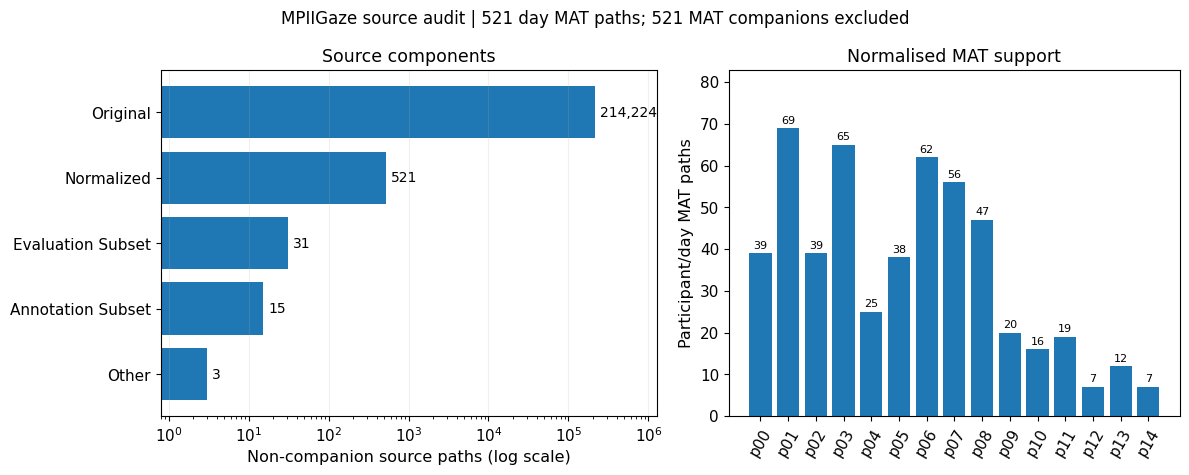

In [9]:
# ==================== 08. Plot Observed Source Inventory =====================

# ------------------------ 1. Source Component Figure -------------------------
counts = scientific.component.value_counts().sort_values()
mat_candidates = inventory.loc[
    inventory.component.eq("Normalized") & inventory.suffix.eq(".mat")]
excluded = int(mat_candidates.relative_path.map(is_archive_companion).sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8),
                         gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
bars = ax.barh(counts.index, counts.values)
ax.set_xscale("log")
ax.set_xlim(0.8, max(counts.max() * 6, 10))
ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=4)
ax.set(xlabel="Non-companion source paths (log scale)",
       title="Source components")
ax.grid(axis="x", alpha=.2)
ax = axes[1]
bars = ax.bar(support.participant_id, support.normalised_mat_files)
ax.bar_label(bars, padding=2, fontsize=8)
ax.set(ylabel="Participant/day MAT paths", title="Normalised MAT support")
ax.set_ylim(0, max(1, support.normalised_mat_files.max() * 1.2))
ax.tick_params(axis="x", rotation=60)
fig.suptitle(f"MPIIGaze source audit | {len(normalized):,} day MAT paths; "
             f"{excluded:,} MAT companions excluded")
fig.tight_layout()
save_figure(fig, output_dir / "01_source_inventory.png")
plt.show()

**09. Interpretation and Output Download**

The audit establishes a source inventory of 15 participants, 521 normalised day containers, 15 representative MAT headers and 45 participant-list files. The six saved outputs include the inventory tables, protocol CSV and source plot. Notebook 02 uses the source inventory to inspect paired eye images and gaze geometry before constructing participant-disjoint folds.

In [10]:
# ================= 09. Interpret Source Evidence and Export ==================

# --------------------- 1. Report Observed Source Support ---------------------
print("Archive paths:", len(inventory))
print("Participant/day MAT paths:", len(normalized))
print("MAT header variables:", len(mat_schema))
print("Participant list paths:", int(lists.file_type.eq("participant_list").sum()))

# ------------------------ 2. Package Current Outputs -------------------------
(output_dir / "01_protocol.json").unlink(missing_ok=True)
download_outputs_from_colab("vision_based_gaze_estimation/output", "01")

Archive paths: 430180
Participant/day MAT paths: 521
MAT header variables: 30
Participant list paths: 45
------------------------------------------------------------------------
Notebook 01
Files packaged: 6
  + 01_evaluation_list_inventory.csv
  + 01_file_inventory.csv
  + 01_mat_schema.csv
  + 01_participant_support.csv
  + 01_protocol.csv
  + 01_source_inventory.png
Download ZIP from Colab Contents: /content/vision_based_gaze_estimation_Notebook_01_Outputs.zip
